# Minimal stored energy in the kernel of the scattering dual, total current as the variable

Bound on the scattered power $\tfrac12 I^H R_0 I$ of a structure carved out of the copper 2:1 plate (`*_patch21ka1.txt`, $ka = 1$ at 2.45 GHz,
plane wave $E_0 = 1$ kV/m), in the RWG basis with $Z_\mathrm{mat} = Z_s L$. The variable is the total current $x = I$, as in
`maxScatIvecNoChol.ipynb` (`nullSpaceMinField.ipynb` uses the scattered voltage).

At copper, the GCD Lagrangian $L^\star = \operatorname{Sym} A(\lambda^\star)$ of the scattering dual has a near-kernel $N$ (orthonormal
eigenvectors with eigenvalues below $\epsilon\,\lambda_\mathrm{max}$). With $S \perp N$ the Lagrangian
$$f_0(I) + \sum_k \lambda_k^\star c_k(I) = D - (I - I^\star)^H L^\star (I - I^\star)$$
is constant on $I = I_r + N y$, where $I_r = (1 - N N^H) I^\star$ is the image part. The kernel component $y$ does not change the scattering dual
objective. It is chosen by a second QCQP in the kernel, which minimizes the stored energy under the same physical constraints:
$$\min_y \omega (W_\mathrm{m} + W_\mathrm{e}) = \tfrac14 I^H \omega W I \quad \text{s.t.} \quad \operatorname{Re}\big(I^H P^H (V - Z_\mathrm{tot} I)\big) = 0, \quad I = I_r + N y .$$
Here $\omega W \succ 0$ is the stored energy matrix (Vandenbosch, AToM `omW`, exported by `exportOmWpatch21ka1.m`, as in `maxScatFixQ.ipynb`).
Current in the kernel stores reactive energy without changing the dual objective. The minimal-energy kernel component therefore suppresses
the spurious (reactive, resonant) currents of the degenerate dual solution and lowers the quality factor
$Q_W = \omega(W_\mathrm{m} + W_\mathrm{e})/P_\mathrm{rad}$.

Steps:
1. global and GCD bounds on the scattered power,
2. the split into image and kernel,
3. the global bound on the minimal stored energy in the kernel ($p = 1$, $p = j$), then GCD in the kernel, and the spectrum of the kernel Lagrangian,
4. pointwise inference and the complex material density of the final (kernel GCD) current.

In [1]:
import contextlib
import copy
import io
import time

import matplotlib.pyplot as plt
import numpy as np
import scipy.io as sio
import scipy.linalg as la
import scipy.sparse as sp
from matplotlib.collections import LineCollection, PolyCollection
from matplotlib.colors import LogNorm
from scipy.optimize import least_squares

from dolphindes.cvxopt import DenseSharedProjQCQP, OptimizationHyperparameters
from dolphindes.cvxopt.gcd import GCDHyperparameters

In [2]:
matrixSet = "patch21ka1" # copper 2:1 plate, ka = 1; omW and the mesh exist for this set only (exportOmWpatch21ka1.m)

# Physical constants
epsilon_0 = 8.854e-12 # F/m
mu_0 = 4e-7 * np.pi # H/m
c = 1/np.sqrt(epsilon_0 * mu_0) # speed of light in vacuum
eta_0 = np.sqrt(mu_0/epsilon_0) # free-space impedance

E0 = 1e3 # plane wave amplitude in V/m

frequency = 2.45e9 # frequency in Hz
omega = 2 * np.pi * frequency # angular frequency

copper_conductivity = 5.96e7 # S/m
delta = np.sqrt(2 / (omega * mu_0 * copper_conductivity)) # skin depth in m
Zs = (1 + 1j) / (copper_conductivity * delta) # surface impedance
print(f"Surface impedance: {Zs} Ω")

Surface impedance: (0.012739130327240646+0.012739130327240646j) Ω


In [3]:
def Msym(M):
    return(0.5*(M.conj().T + M))

# Load matrices from text files (original RWG basis, no Cholesky transformation)
Lmat = np.loadtxt(f"Lmat_{matrixSet}.txt", delimiter=',') # lossy matrix
R0 = Msym(np.loadtxt(f"R0_{matrixSet}.txt", delimiter=',')) # radiated power matrix
X0 = Msym(np.loadtxt(f"X0_{matrixSet}.txt", delimiter=',')) # reactive power matrix
omW = Msym(np.loadtxt(f"omW_{matrixSet}.txt", delimiter=',')) # stored energy matrix, omega (Wm + We) = I^H omW I / 4
Vinc = E0*np.loadtxt(f"V_{matrixSet}.txt", delimiter=',').astype(complex) # voltage excitation vector

Ndes = Lmat.shape[0] # number of design variables
print(f"Matrix set: {matrixSet}, number of design variables: {Ndes}")

Zmat = Zs * Lmat # material impedance matrix (non-diagonal)
Z0 = R0 + 1j*X0 # free-space impedance matrix
Ztot = Z0 + Zmat # total impedance matrix
Ldiag = np.diag(Lmat).copy() # diagonal of the lossy matrix

def evalObj(Ivec):
    # scattered (radiated) power
    return(0.5*np.real(Ivec.conj() @ R0 @ Ivec))

# full plate performance
Ifull = np.linalg.solve(Ztot, Vinc)
Pfull = evalObj(Ifull)
print(f"Objective for full plate: {Pfull:.6e} W")

# reference: lossless resonant electric dipole, sigma_sca = 3 lambda^2 / (2 pi)
Pdip = 3*(c/frequency)**2/(2*np.pi) * E0**2/(2*eta_0)
print(f"resonant dipole scattered power: {Pdip:.4f} W")

Matrix set: patch21ka1, number of design variables: 233
Objective for full plate: 4.114174e-02 W
resonant dipole scattered power: 9.4884 W


In [4]:
# mesh of the operators (exportOmWpatch21ka1.m): bf[n] = [T+, T-, edge node 1, edge node 2], 0 based
mesh = sio.loadmat(f"mesh_{matrixSet}.mat")
nodes, tria, bf = mesh["nodes"], mesh["triangles"], mesh["bf"]
edgeLen = np.linalg.norm(nodes[bf[:, 2]] - nodes[bf[:, 3]], axis=1)
e1, e2 = nodes[tria[:, 1]] - nodes[tria[:, 0]], nodes[tria[:, 2]] - nodes[tria[:, 0]]
triArea = 0.5*np.abs(e1[:, 0]*e2[:, 1] - e1[:, 1]*e2[:, 0])
triCent = nodes[tria].mean(axis=1)
freeNode = np.array([[np.setdiff1d(tria[t], bf[n, 2:])[0] for t in bf[n, :2]] for n in range(Ndes)]) # free vertices of T+, T-
print(f"{len(nodes)} nodes, {len(tria)} triangles, plate {np.ptp(nodes[:, 0])*1e3:.2f} x {np.ptp(nodes[:, 1])*1e3:.2f} mm, "
      f"Lmat_nn = 0.481 l_n^2 (equilateral RWG): max rel. error {np.max(np.abs(Ldiag/(5/(6*np.sqrt(3))*edgeLen**2) - 1)):.1e}")

def currentDensity(I):
    # RWG current density at the triangle centroids, J = I_n l_n rho / (2 A)
    J = np.zeros((len(tria), 2), dtype=complex)
    for s, sgn in [(0, 1), (1, -1)]:
        rho = sgn*(triCent[bf[:, s]] - nodes[freeNode[:, s]])
        np.add.at(J, bf[:, s], (I*edgeLen/(2*triArea[bf[:, s]]))[:, None]*rho)
    return J

def plotStructure(ax, keep, I, title=""):
    # metal triangles colored by |J| (log); removed RWG functions between metal triangles are slots (red), void triangles white
    metal = np.zeros(len(tria), dtype=bool)
    metal[bf[keep, :2].ravel()] = True
    J = np.linalg.norm(np.abs(currentDensity(I)), axis=1)
    pc = PolyCollection(nodes[tria[metal]], array=np.maximum(J[metal], 1e-3*J.max()), cmap='viridis',
                        norm=LogNorm(1e-3*J.max(), J.max()), edgecolors='none')
    ax.add_collection(pc)
    ax.add_collection(PolyCollection(nodes[tria[~metal]], facecolors='white', edgecolors='0.85', linewidths=0.3))
    slot = ~keep & metal[bf[:, 0]] & metal[bf[:, 1]]
    ax.add_collection(LineCollection(nodes[bf[slot, 2:]], colors='r', linewidths=1.5))
    ax.set_xlim(nodes[:, 0].min(), nodes[:, 0].max()); ax.set_ylim(nodes[:, 1].min(), nodes[:, 1].max())
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=9)
    return pc

def plotDensity(ax, d, title=""):
    # inferred density on the RWG edges
    lc = LineCollection(nodes[bf[:, 2:]], array=np.log10(np.maximum(d, 1e-6)), cmap='viridis', linewidths=2.5)
    lc.set_clim(-6, 0)
    ax.add_collection(lc)
    ax.set_xlim(nodes[:, 0].min(), nodes[:, 0].max()); ax.set_ylim(nodes[:, 1].min(), nodes[:, 1].max())
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=9)
    return lc

def plotComplexDensity(axes, d, title=""):
    # complex density on the RWG edges: Re d (1 metal, 0 void) and Im d (0 for any structure), on a common symmetric scale
    dmax = np.quantile(np.abs(d), 0.99)
    for ax, part, name in [(axes[0], d.real, "Re d"), (axes[1], d.imag, "Im d")]:
        lc = LineCollection(nodes[bf[:, 2:]], array=part, cmap='RdBu_r', linewidths=2.5)
        lc.set_clim(-dmax, dmax)
        ax.add_collection(lc)
        ax.set_xlim(nodes[:, 0].min(), nodes[:, 0].max()); ax.set_ylim(nodes[:, 1].min(), nodes[:, 1].max())
        ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"{title}: {name}, scale \u00b1{dmax:.1e}", fontsize=8)
        plt.colorbar(lc, ax=ax, shrink=0.8, format='%.0e')
    return lc

104 nodes, 168 triangles, plate 35.05 x 17.00 mm, Lmat_nn = 0.481 l_n^2 (equilateral RWG): max rel. error 2.6e-14


## Scattering QCQP, global and GCD bounds

As in `maxScatIvecNoChol.ipynb`: $A_0 = -\tfrac12 R_0$, and the projector constraints
$\operatorname{Re}(-I^H A_1 P I + 2 I^H P^H s_1) = 0$ with $A_1 = Z_\mathrm{tot}^H$, $A_2 = 1$, $s_1 = \tfrac12 V$, i.e.
$\operatorname{Re}\sum_i p_i^* w_i = 0$, $w_i = I_i^*(V - Z_\mathrm{tot} I)_i$ (the same constraints as in the scattered-voltage form). The global bound uses $p = \mathbf 1$ and $p = j\mathbf 1$; GCD adds
two diagonal projectors per iteration (20 iterations, no merging). GCD is slightly non-deterministic (ARPACK starts and the random
`Pstruct` coefficients).

In [5]:
Obj = -0.5 * R0
obj = np.zeros(Ndes, dtype=complex)
obj0 = 0.0
A1 = Ztot.conj().T
A2 = np.eye(Ndes, dtype=complex) # identity, explicit for projectorForm
s1 = 0.5 * Vinc

def VtoI(I):
    return I # the variable is the current

Astored = 0.25*omW # omega (Wm + We) = I^H Astored I

def storedOf(I):
    return np.real(I.conj() @ Astored @ I)

def evalQW(I):
    return storedOf(I)/evalObj(I) # omega (Wm + We) / P_rad

def localViolation(I):
    # pointwise w_i = I_i^* (V - Ztot I)_i, zero for any structure made of enabled basis functions
    return(np.conj(I)*(Vinc - Ztot @ I))

def constraintRes(Q, x):
    # c_k(x) = Re(-x^H A_k x + 2 x^H F_k) + c_k for all constraints (W), zero for a feasible x
    res = np.real(-x.conj() @ Q._allA_at_v(x) + 2*x.conj() @ Q.Fs)
    res[Q.n_proj_constr:] += Q.c_2j
    return res

def lagSpectrum(Q):
    return np.linalg.eigvalsh(Msym(Q._get_total_A(Q.current_lags)))

opt_params = OptimizationHyperparameters(opttol=1e-8,
    gradConverge=True,
    min_inner_iter=10,
    max_restart=20,
    penalty_ratio=1e-2,
    penalty_reduction=0.1,
    break_iter_period=5,
    verbose=0)

np.random.seed(0)
PlistGlob = [sp.diags(q*np.ones(Ndes, dtype=complex)) for q in [1, 1j]] # global real and reactive power
Qglob = DenseSharedProjQCQP(Obj, obj, obj0, A1, s1, PlistGlob, A2=A2, verbose=0)
Qglob.solve_current_dual_problem(method='newton', init_lags=np.array([1.0, 0.0]), opt_params=opt_params)

Ngcd = 20 # number of GCD iterations
Qgcd = copy.deepcopy(Qglob)
gcd_params = GCDHyperparameters(max_proj_cstrt_num=2 + 2*Ngcd,
    max_gcd_iter_num=Ngcd,
    gcd_iter_period=Ngcd + 1, # no early termination
    opt_params=opt_params)
t1 = time.time()
with contextlib.redirect_stdout(io.StringIO()): # silence the per-iteration GCD output
    Qgcd.run_gcd(gcd_params)
print(f"GCD: {time.time() - t1:.1f}s")

for name, Q in [("global", Qglob), (f"GCD {Ngcd}", Qgcd)]:
    lam = lagSpectrum(Q)
    I = VtoI(Q.current_xstar)
    print(f"{name}: D {Q.current_dual:.6e} W ({Q.current_dual/Pdip:.2f} x resonant dipole), {Q.n_proj_constr} constraints, "
          f"min/max eig L* {lam[0]/lam[-1]:.1e}, ||c_global(I*)||/D {np.linalg.norm(constraintRes(Qglob, Q.current_xstar))/Q.current_dual:.1e}, "
          f"max|w_i|/|I^H V| {np.abs(localViolation(I)).max()/np.abs(I.conj() @ Vinc):.1e}, Q_W {storedOf(I)/evalObj(I):.1f}")

GCD: 50.3s
global: D 1.847944e+01 W (1.95 x resonant dipole), 2 constraints, min/max eig L* 9.9e-04, ||c_global(I*)||/D 1.2e-04, max|w_i|/|I^H V| 4.0e+01, Q_W 318.4
GCD 20: D 1.769636e+01 W (1.87 x resonant dipole), 42 constraints, min/max eig L* 5.3e-11, ||c_global(I*)||/D 2.1e+02, max|w_i|/|I^H V| 3.6e+01, Q_W 254.2


## Image and kernel

The near-kernel $N$ of the GCD $L^\star$ for several $\epsilon$. The eigenvalues are those of the current-variable Lagrangian, which is
congruent to the scattered-voltage one ($L_I = Z_0^H L_x Z_0$), so its relative spectrum differs from `nullSpaceMinField.ipynb`.

eps 1e-06: kernel dimension 1
eps 1e-04: kernel dimension 6
eps 1e-02: kernel dimension 166


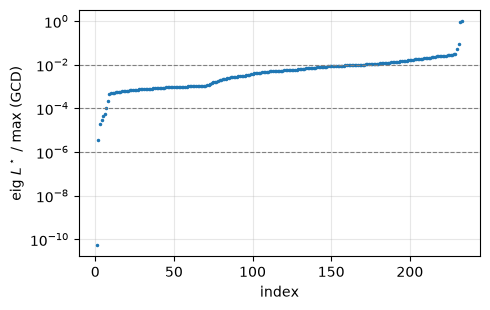

In [6]:
lamGCD, UGCD = np.linalg.eigh(Msym(Qgcd._get_total_A(Qgcd.current_lags)))
kerTols = [1e-6, 1e-4, 1e-2]

def splitKernel(kerTol):
    # kernel N of the GCD L* and the image part x_r of x*
    N = UGCD[:, lamGCD < kerTol*lamGCD[-1]]
    xs = Qgcd.current_xstar
    return N, xs - N @ (N.conj().T @ xs)

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.semilogy(np.arange(1, Ndes + 1), lamGCD/lamGCD[-1], '.', ms=3)
for t in kerTols:
    ax.axhline(t, ls='--', c='gray', lw=0.8)
    print(f"eps {t:.0e}: kernel dimension {splitKernel(t)[0].shape[1]}")
ax.set_xlabel('index'); ax.set_ylabel(r'eig $L^\star$ / max (GCD)'); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

## Minimal stored energy in the kernel: global bound and GCD

In $y \in \mathbb C^K$ the stored energy is $E(y) = \tfrac14 (I_r + N y)^H \omega W (I_r + N y)$ (in W, $\omega$ times the energy). The QCQP maximizes
$-E$, with $A_0 = \tfrac14 N^H \omega W N \succ 0$, $s_0 = -\tfrac14 N^H \omega W I_r$ and $c_0 = -E(I_r)$ (`shiftForm`). Its dual $D_F$ gives the lower bound
$-D_F$ on the minimal stored energy. Every projector constraint at $I = I_r + N y$ is a general constraint in $y$
(`projectorForm`). Since $A_0 \succ 0$, $\lambda = 0$ is dual feasible.

1. **Global.** The constraints $p = \mathbf 1$ and $p = j\mathbf 1$.
2. **GCD in the kernel.** This is `kernelGCD` of `nullSpaceQCQP.ipynb`. Each iteration evaluates the max-violation and min-eigenvalue
   projectors at $I_r + N y^\star$, orthogonalizes them against the span of the current constraint functions and adds them with
   multiplier 0. Leading constraints are merged once there are too many, and the dual is re-solved.

   The constraint functions of $y$ span at most $(K + 1)^2$ real dimensions. The library dual solver has no iteration limit, so
   `solveReduced` caps the dual evaluations at 3000 and keeps the lowest dual seen. A capped value is not a converged dual.

**Kernel of the kernel problem.** The Lagrangian $A_0 + \sum_k \lambda_k B_k$ is positive definite at $\lambda = 0$; its spectrum at the optimum
shows whether the minimal-energy problem has a kernel of its own.

The minimal-energy bound applies only to currents with the image part $I_r$ fixed. The scattering bound $D$ is still the bound on all
structures.

In [7]:
def qcqpParts(Q):
    # objective (A0, s0, c0) and constraints [(A_k, F_k, c_k)], f(x) = -x^H A x + 2 Re(x^H s) + c
    ck = np.r_[np.zeros(Q.n_proj_constr), Q.c_2j]
    cons = [(Msym(np.asarray(Ak)), Q.Fs[:, k].copy(), ck[k]) for k, Ak in enumerate(Q.precomputed_As)]
    return (Msym(np.asarray(Q.A0)), Q.s0.copy(), float(Q.c0)), cons

def shiftForm(A, s, c, x0, N):
    # f(x0 + N y) in the same form, in y
    Ax0 = A @ x0
    return Msym(N.conj().T @ A @ N), N.conj().T @ (s - Ax0), float(np.real(-x0.conj() @ Ax0 + 2*x0.conj() @ s) + c)

def generalQCQP(objective, cons):
    # QCQP with only general constraints (A2 = 1), objective (A0, s0, c0) and constraints [(B_j, s_2j, c_2j)]
    A0r, s0r, c0r = objective
    K = len(s0r)
    return DenseSharedProjQCQP(A0r, s0r, c0r, np.eye(K, dtype=complex), np.zeros(K, dtype=complex), [], Pstruct=sp.eye(K),
                               B_j=[c[0] for c in cons], s_2j=[c[1] for c in cons], c_2j=np.array([c[2] for c in cons]), verbose=0)

def consVec(con):
    # real coordinates of the constraint function -y^H B y + 2 Re(y^H s) + c
    B, s, c = con
    return np.r_[B.real.ravel(), B.imag.ravel(), s.real, s.imag, c]

def setLags(Q, lags):
    Q.current_lags = lags
    Q.current_dual = Q.get_dual(lags)[0]
    Q.current_xstar = Q._get_xstar(lags)[0]

class EvalCap(Exception):
    pass

def solveReduced(Qr, lags, maxEval=3000):
    # start from (1 + t) lags, the smallest |t| in the list that is strictly dual feasible (t < 0 shrinks toward lambda = 0, feasible for A0 > 0). The optimizer has no iteration limit and a
    # reduced dual can be unbounded below (infeasible restricted primal, see Kernel GCD), so get_dual is capped at maxEval calls and
    # the multipliers with the lowest unpenalized dual seen are kept. Returns t and whether the cap was hit.
    t = next(t for t in [1e-6, -1e-6, 1e-4, -1e-4, 1e-2, -1e-2, 0.1, -0.1, 1.0, -0.5, 10.0, -1.0] if Qr.is_dual_feasible((1 + t)*lags))
    l0 = (1 + t)*lags
    best = [Qr.get_dual(l0)[0], l0.copy()]
    count = [0]
    getDual = Qr.get_dual
    def cappedDual(l, *args, **kwargs):
        count[0] += 1
        if count[0] > maxEval:
            raise EvalCap
        out = getDual(l, *args, **kwargs)
        D = out[0] if not kwargs.get("penalty_vectors") else getDual(l)[0]
        if D < best[0]:
            best[0], best[1] = D, np.array(l, dtype=float).copy()
        return out
    Qr.get_dual = cappedDual
    capped = False
    try:
        Qr.solve_current_dual_problem(method='newton', init_lags=l0, opt_params=opt_params)
    except EvalCap:
        capped = True
    finally:
        del Qr.get_dual
    if capped or Qr.current_dual > best[0]:
        setLags(Qr, best[1])
    return t, capped

def projectorForm(p, a, B):
    # diagonal projector constraint Re(-x^H A1 P A2 x + 2 x^H A2^H P^H s1) at x = a + B y, as a general constraint in y
    return shiftForm(Msym(A1 @ (p[:, None]*A2)), A2.conj().T @ (np.conj(p)*s1), 0.0, a, B)

def addConstraint(cons, lags, new, tol=1e-8):
    # new constraint orthogonal to the span of cons, normalized, multiplier 0; dropped if it lies in the span
    M = np.array([consVec(cn) for cn in cons]).T
    v = consVec(new)
    g = np.linalg.lstsq(M, v, rcond=None)[0]
    B, s, c = new
    for gk, (Bk, sk, ck) in zip(g, cons):
        B, s, c = B - gk*Bk, s - gk*sk, c - gk*ck
    nrm = np.linalg.norm(consVec((B, s, c)))
    if nrm < tol*np.linalg.norm(v):
        return cons, lags, False
    return cons + [(B/nrm, s/nrm, c/nrm)], np.r_[lags, 0.0], True

def mergeLead(cons, lags, m):
    # the first m constraints merged by their multipliers into one (normalized), the dual is unchanged
    merged = [sum(l*cn[i] for l, cn in zip(lags[:m], cons[:m])) for i in range(3)]
    nrm = np.linalg.norm(consVec(merged))
    return [tuple(t/nrm for t in merged)] + cons[m:], np.r_[nrm, lags[m:]]

def kernelGCD(Qr, a, B, nIter=20, maxCon=None):
    # GCD inside the kernel x = a + B y of a reduced QCQP with general constraints only
    objective, cons = qcqpParts(Qr)
    maxCon = maxCon or len(cons) + 2*nIter
    hist, added, capped = [Qr.current_dual], 0, 0
    for it in range(nIter):
        lags = Qr.current_lags.copy()
        x = a + B @ Qr.current_xstar
        pV = (2*s1 - A1.conj().T @ x) * np.conj(A2 @ x) # max-violation projector
        u = np.linalg.eigh(Msym(Qr._get_total_A(lags)))[1][:, 0]
        v = B @ u
        pE = (A1.conj().T @ v) * np.conj(A2 @ v) # min-eigenvalue projector, unit modulus
        pE = np.divide(pE, np.abs(pE), out=np.zeros_like(pE), where=np.abs(pE) > 0)
        n0 = len(cons)
        for p in [pV, pE]:
            cons, lags, ok = addConstraint(cons, lags, projectorForm(p, a, B))
        if len(cons) == n0: # both projectors already in the span
            break
        added += len(cons) - n0
        if len(cons) > maxCon:
            cons, lags = mergeLead(cons, lags, len(cons) - maxCon + 1)
        Qr = generalQCQP(objective, cons)
        capped += solveReduced(Qr, lags)[1]
        hist.append(Qr.current_dual)
    return Qr, dict(hist=np.array(hist), added=added, capped=capped)

In [8]:
NgcdKer = 20 # GCD iterations in the kernel
pGlob = [np.ones(Ndes, dtype=complex), 1j*np.ones(Ndes, dtype=complex)]

Aloss = 0.5*Zs.real*Lmat # P_loss = I^H Aloss I

def lossOf(I):
    return np.real(I.conj() @ Aloss @ I)

def fieldOf(I):
    return np.linalg.norm(Vinc - Z0 @ I)**2 # total voltage V + V_sca

def kernelReport(name, x, Qk=None):
    # the current in the full space: field, scattering objective and Lagrangian, root GCD residuals, pointwise violation
    e = x - Qgcd.current_xstar
    Lag = Qgcd.current_dual - np.real(e.conj() @ Msym(Qgcd._get_total_A(Qgcd.current_lags)) @ e)
    I = VtoI(x)
    s = (f"    {name:22s}: stored / stored(I*) {storedOf(x)/storedOf(Qgcd.current_xstar):.3e}, Q_W {evalQW(x):.1f}, loss / loss(I*) {lossOf(x)/lossOf(Qgcd.current_xstar):.3e}, field / field(I*) {np.sqrt(fieldOf(x)/fieldOf(Qgcd.current_xstar)):.3f}, P/D {evalObj(I)/Qgcd.current_dual:.6f}, "
         f"Lagrangian/D {Lag/Qgcd.current_dual:.6f}, "
         f"max|w_i|/|I^H V| {np.abs(localViolation(I)).max()/np.abs(I.conj() @ Vinc):.1e}")
    if Qk is not None:
        lam = lagSpectrum(Qk)
        s += (f"\n    {'':22s}  stored-energy bound -D_F {-Qk.current_dual:.3e} W, stored {storedOf(x):.3e} W, "
              f"{Qk.n_gen_constr} constraints, ||c_global||/D {np.linalg.norm(constraintRes(Qglob, x))/Qgcd.current_dual:.1e}, "
              f"kernel Lagrangian min/max eig {lam[0]/lam[-1]:.1e}, near-kernel dim (eps) {np.count_nonzero(lam < kerTol*lam[-1])}")
    print(s)

kernel = {}
for kerTol in kerTols:
    N, xr = splitKernel(kerTol)
    K = N.shape[1]
    objective = shiftForm(Astored, np.zeros(Ndes, dtype=complex), 0.0, xr, N)
    yFree = np.linalg.solve(objective[0], objective[1]) # unconstrained minimizer
    print(f"eps {kerTol:.0e}, K {K}: stored energy of I* {storedOf(Qgcd.current_xstar):.3e} W (Q_W {evalQW(Qgcd.current_xstar):.1f}), "
          f"of I_r {storedOf(xr):.3e} W, unconstrained min {storedOf(xr + N @ yFree):.3e} W (Q_W {evalQW(xr + N @ yFree):.1f})")
    t1 = time.time()
    Qk = generalQCQP(objective, [projectorForm(p, xr, N) for p in pGlob])
    capG = solveReduced(Qk, np.zeros(2))[1]
    kernelReport("kernel global", xr + N @ Qk.current_xstar, Qk)
    t2 = time.time()
    try:
        Qkg, info = kernelGCD(copy.deepcopy(Qk), xr, N, NgcdKer)
    except np.linalg.LinAlgError as err: # a capped reduced solve can end at extreme multipliers
        print(f"    kernel GCD failed ({err})")
        Qkg, info = None, None
    if Qkg is not None:
        kernelReport(f"kernel GCD ({time.time() - t2:.0f}s)", xr + N @ Qkg.current_xstar, Qkg)
        print(f"    {'':22s}  +{info['added']} constraints, capped solves {int(capG) + info['capped']}, "
              f"stored-energy bound -D_F: global -> GCD {-Qk.current_dual:.4e} -> {-Qkg.current_dual:.4e} W")
    kernel[kerTol] = dict(N=N, xr=xr, Qk=Qk, Qkg=Qkg, info=info)

eps 1e-06, K 1: stored energy of I* 4.498e+03 W (Q_W 254.2), of I_r 4.219e+03 W, unconstrained min 4.163e+03 W (Q_W 235.2)


    kernel global         : stored / stored(I*) 1.202e+00, Q_W 305.5, loss / loss(I*) 1.005e+00, field / field(I*) 1.340, P/D 0.999961, Lagrangian/D 1.000000, max|w_i|/|I^H V| 5.8e+01
                            stored-energy bound -D_F 5.407e+03 W, stored 5.407e+03 W, 2 constraints, ||c_global||/D 5.4e-05, kernel Lagrangian min/max eig 1.0e+00, near-kernel dim (eps) 0


/Users/xjliska/GIT/dolphindes/.venv/lib/python3.12/site-packages/scipy/sparse/linalg/_eigen/arpack/arpack.py:1664: RuntimeWarning: k >= N - 1 for N * N square matrix. Attempting to use scipy.linalg.eig instead.
  ret = eigs(A, k, M=M, sigma=sigma, which=which, v0=v0,


    kernel GCD (0s)       : stored / stored(I*) 9.408e-01, Q_W 239.1, loss / loss(I*) 9.960e-01, field / field(I*) 0.878, P/D 1.000096, Lagrangian/D 1.000000, max|w_i|/|I^H V| 3.1e+01
                            stored-energy bound -D_F 4.570e+197 W, stored 4.232e+03 W, 4 constraints, ||c_global||/D 2.7e+02, kernel Lagrangian min/max eig 1.0e+00, near-kernel dim (eps) 0
                            +2 constraints, capped solves 1, stored-energy bound -D_F: global -> GCD 5.4067e+03 -> 4.5700e+197 W
eps 1e-04, K 6: stored energy of I* 4.498e+03 W (Q_W 254.2), of I_r 4.151e+03 W, unconstrained min 3.972e+03 W (Q_W 224.5)
    kernel global         : stored / stored(I*) 1.199e+00, Q_W 304.8, loss / loss(I*) 1.005e+00, field / field(I*) 1.337, P/D 0.999888, Lagrangian/D 0.999953, max|w_i|/|I^H V| 5.9e+01
                            stored-energy bound -D_F 5.393e+03 W, stored 5.393e+03 W, 2 constraints, ||c_global||/D 1.2e-04, kernel Lagrangian min/max eig 8.0e-01, near-kernel dim (eps) 0


    kernel GCD (1s)       : stored / stored(I*) 1.070e+00, Q_W 272.3, loss / loss(I*) 9.889e-01, field / field(I*) 1.111, P/D 0.998564, Lagrangian/D 0.999872, max|w_i|/|I^H V| 5.0e+01
                            stored-energy bound -D_F 3.061e+25 W, stored 4.811e+03 W, 10 constraints, ||c_global||/D 1.4e+02, kernel Lagrangian min/max eig 1.3e-01, near-kernel dim (eps) 0
                            +8 constraints, capped solves 1, stored-energy bound -D_F: global -> GCD 5.3927e+03 -> 3.0609e+25 W
eps 1e-02, K 166: stored energy of I* 4.498e+03 W (Q_W 254.2), of I_r 4.227e+02 W, unconstrained min 3.402e+02 W (Q_W 24.5)
    kernel global         : stored / stored(I*) 1.195e-01, Q_W 37.9, loss / loss(I*) 1.637e-01, field / field(I*) 0.275, P/D 0.801743, Lagrangian/D 0.796480, max|w_i|/|I^H V| 1.0e+01
                            stored-energy bound -D_F 5.373e+02 W, stored 5.373e+02 W, 2 constraints, ||c_global||/D 3.4e-06, kernel Lagrangian min/max eig 4.1e-04, near-kernel dim (eps) 49


    kernel GCD (38s)      : stored / stored(I*) 3.764e-01, Q_W 111.8, loss / loss(I*) 3.933e-01, field / field(I*) 0.558, P/D 0.856189, Lagrangian/D 0.921853, max|w_i|/|I^H V| 1.2e+01
                            stored-energy bound -D_F 2.508e+03 W, stored 1.693e+03 W, 42 constraints, ||c_global||/D 6.4e+01, kernel Lagrangian min/max eig 1.7e-12, near-kernel dim (eps) 23
                            +40 constraints, capped solves 0, stored-energy bound -D_F: global -> GCD 5.3732e+02 -> 2.5084e+03 W


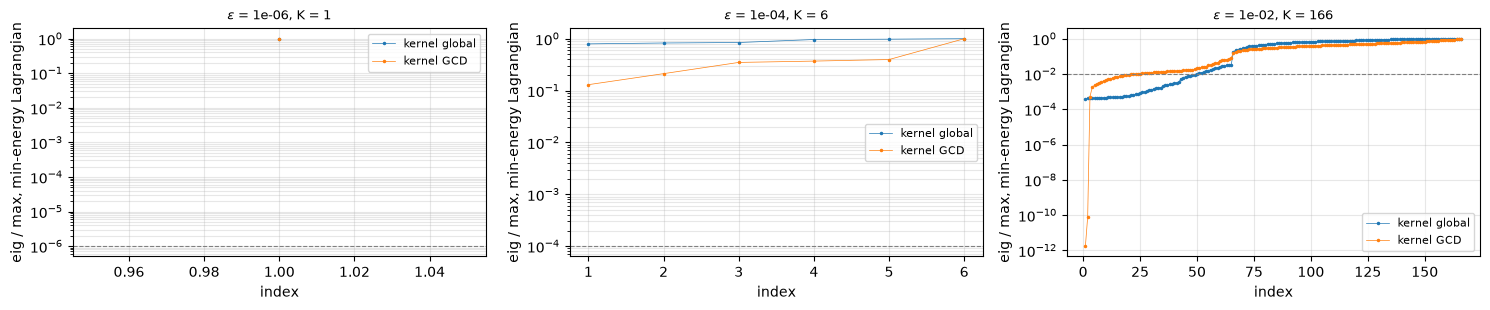

In [9]:
fig, axes = plt.subplots(1, len(kerTols), figsize=(5*len(kerTols), 3.2))
for ax, kerTol in zip(np.atleast_1d(axes), kerTols):
    r = kernel[kerTol]
    for name, Q in [("kernel global", r["Qk"]), ("kernel GCD", r["Qkg"])]:
        if Q is not None:
            lam = lagSpectrum(Q)
            ax.semilogy(np.arange(1, len(lam) + 1), lam/lam[-1], '.-', ms=3, lw=0.5, label=name)
    ax.axhline(kerTol, ls='--', c='gray', lw=0.8)
    ax.set_xlabel('index'); ax.set_ylabel('eig / max, min-energy Lagrangian'); ax.set_title(rf"$\epsilon$ = {kerTol:.0e}, K = {r['N'].shape[1]}", fontsize=9)
    ax.legend(fontsize=8); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

## Pointwise inference and the complex material density

The admittance form of a basis function with relaxed density $d$ is $Z_s L_{ii} I_i = d_i u_i$, where $u = V - Z_\mathrm{tot} I + Z_s L_{ii} I$ is the
driving voltage without the material self term. For a given current, the **complex density**
$$d_i = \frac{Z_s L_{ii} I_i}{u_i}$$
is $1$ on metal and $0$ where the basis function is removed: any structure has $\operatorname{Re} d \in \{0, 1\}$ and $\operatorname{Im} d = 0$.

The pointwise fits project it:
- the admittance form takes $\operatorname{clip}(\operatorname{Re} d, 0, 1)$;
- the impedance form projects the series impedance $r_i = (V - Z_\mathrm{tot} I)_i/I_i$ onto the passive ray, $d_i = 1/(1 + t_i)$.

Each relaxed design is rounded with thresholds $t \in [10^{-6}, 1)$, and the binary design with the largest scattered power is kept.

In [10]:
dMin = 1e-6 # basis functions with d_i < dMin are removed in the realized structure
thsLog = np.logspace(-6, 0, 61)[:-1] # thresholds for binary rounding of d

def complexDensity(I):
    u = Vinc - Ztot @ I + Zs*Ldiag*I
    return Zs*Ldiag*I/u

def inferDimp(I):
    # impedance form: series impedance projected onto the passive ray, d = 1/(1 + t)
    nz = I != 0
    r = np.zeros(Ndes, dtype=complex)
    r[nz] = (Vinc - Ztot @ I)[nz]/I[nz]
    t = np.maximum(0, np.real(np.conj(Zs)*r)/(np.abs(Zs)**2*Ldiag))
    return np.where(nz, 1/(1 + t), 0.0)

def inferDadm(I):
    # admittance form: real part of the complex density, clipped
    return np.clip(complexDensity(I).real, 0, 1)

def realizedCurrent(d):
    # (Ztot + diag(Zs Lii (1/d - 1))) I = V on the kept basis functions, I = 0 elsewhere
    keep = d >= dMin
    I = np.zeros(Ndes, dtype=complex)
    Zd = Ztot + np.diag(Zs*Ldiag*(1/np.maximum(d, dMin) - 1))
    I[keep] = np.linalg.solve(Zd[np.ix_(keep, keep)], Vinc[keep])
    return I

def bestBinary(d):
    designs = [d > t for t in thsLog]
    currents = [realizedCurrent(k.astype(float)) for k in designs]
    Pb = np.array([evalObj(I) for I in currents])
    k = int(np.argmax(Pb))
    return dict(keep=designs[k], I=currents[k], P=Pb[k], th=thsLog[k])

# check: the complex density of the full plate is 1
print(f"full plate: max |d - 1| = {np.abs(complexDensity(Ifull) - 1).max():.1e}")

# the final solution of every kernel split: kernel GCD (kernel global if GCD failed)
currents = {}
for kerTol, r in kernel.items():
    final = "kernel GCD" if r["Qkg"] is not None else "kernel global"
    currents[f"{final}, eps {kerTol:.0e}"] = r["xr"] + r["N"] @ (r["Qkg"] if r["Qkg"] is not None else r["Qk"]).current_xstar

inference = {}
for name, x in currents.items():
    I = VtoI(x)
    d = complexDensity(I)
    inference[name] = dict(d=d, **{form: bestBinary(infer(I)) for form, infer in [("impedance form", inferDimp), ("admittance form", inferDadm)]})
    print(f"{name:26s}: Re d quantiles 10/50/90/max " + "/".join(f"{q:.1e}" for q in np.quantile(d.real, [0.1, 0.5, 0.9, 1.0]))
          + f", Re d > 0.5: {np.count_nonzero(d.real > 0.5):3d}, median |Im d| {np.median(np.abs(d.imag)):.1e}, "
          + ", ".join(f"{form} P/D {inference[name][form]['P']/Qgcd.current_dual:.4f} ({inference[name][form]['P']:.3e} W)"
                      for form in ["impedance form", "admittance form"]))

full plate: max |d - 1| = 1.2e-09
kernel GCD, eps 1e-06     : Re d quantiles 10/50/90/max -2.5e-04/-1.4e-05/3.1e-04/4.6e-03, Re d > 0.5:   0, median |Im d| 7.6e-05, impedance form P/D 0.0023 (4.142e-02 W), admittance form P/D 0.0001 (2.164e-03 W)
kernel GCD, eps 1e-04     : Re d quantiles 10/50/90/max -2.2e-04/-1.1e-05/2.6e-04/9.1e-03, Re d > 0.5:   0, median |Im d| 6.9e-05, impedance form P/D 0.0029 (5.051e-02 W), admittance form P/D 0.0001 (2.284e-03 W)
kernel GCD, eps 1e-02     : Re d quantiles 10/50/90/max -1.4e-04/-1.0e-05/1.5e-04/8.4e-04, Re d > 0.5:   0, median |Im d| 4.6e-05, impedance form P/D 0.0029 (5.168e-02 W), admittance form P/D 0.0001 (1.206e-03 W)


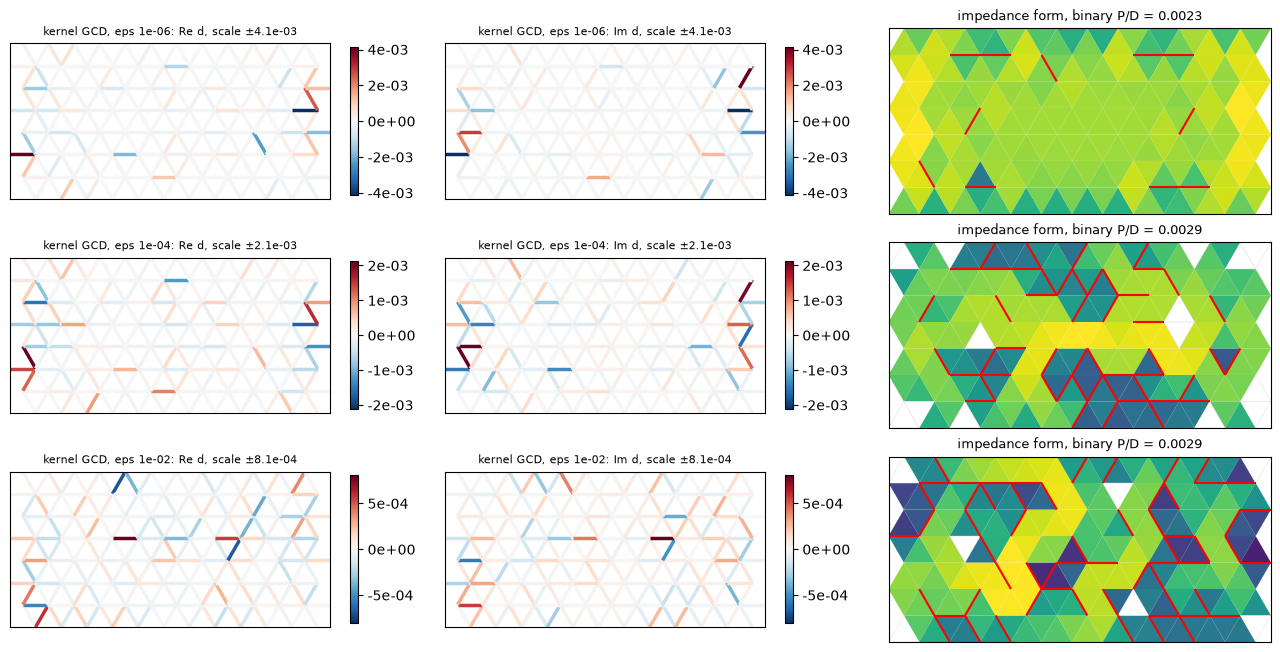

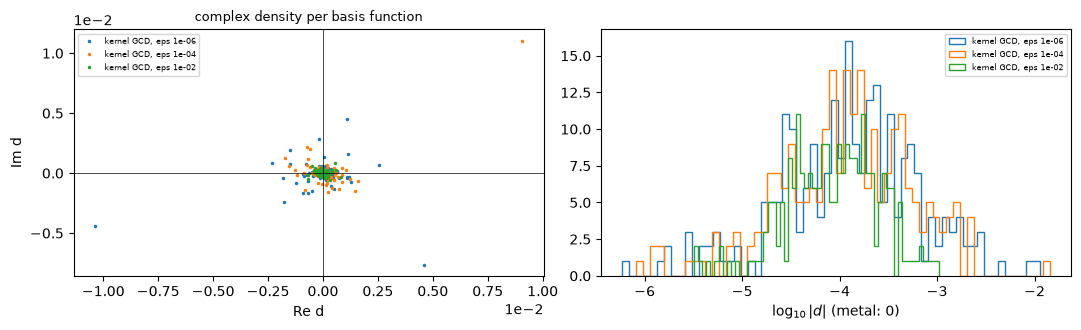

In [11]:
names = list(inference)
fig, axes = plt.subplots(len(names), 3, figsize=(13, 2.2*len(names)))
for row, name in zip(axes, names):
    r = inference[name]
    plotComplexDensity(row[:2], r["d"], name)
    form = max(["impedance form", "admittance form"], key=lambda f: r[f]["P"])
    plotStructure(row[2], r[form]["keep"], r[form]["I"], f"{form}, binary P/D = {r[form]['P']/Qgcd.current_dual:.4f}")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for name in names:
    d = inference[name]["d"]
    axes[0].plot(d.real, d.imag, '.', ms=3, label=name)
axes[0].axvline(0, c='k', lw=0.5); axes[0].axhline(0, c='k', lw=0.5); axes[0].ticklabel_format(style='sci', scilimits=(0, 0))
axes[0].set_xlabel('Re d'); axes[0].set_ylabel('Im d'); axes[0].legend(fontsize=6); axes[0].set_title('complex density per basis function', fontsize=9)
for name in names:
    axes[1].hist(np.log10(np.abs(inference[name]["d"])), bins=60, histtype='step', label=name)
axes[1].set_xlabel(r'$\log_{10}|d|$ (metal: 0)'); axes[1].legend(fontsize=6)
plt.tight_layout(); plt.show()

## Conclusions

These are the numbers of one run; GCD is not exactly reproducible.

**Scattering bounds.** The global bound is 18.48 W ($Q_W = 318$ for its dual current) and GCD gives 17.70 W.
- The GCD dual current has $Q_W = 254$, i.e. stored energy $\omega(W_\mathrm{m} + W_\mathrm{e}) = 4.5$ kW.
- It violates the global power balance by $210\,D$.
- The near-kernel of the current-variable $L^\star$ has dimension 1, 6 and 166 at $\epsilon = 10^{-6}$, $10^{-4}$ and $10^{-2}$.

**Global bound on the minimal stored energy in the kernel.**
- **Strongly dual.** In every case the bound equals the energy of its dual current, and the global residuals vanish ($\|c\|/D \leq 10^{-4}$).
- **True kernel ($K = 1, 6$).** Minimizing the energy alone would lower $Q_W$ only to 235 and 225. With the power balance enforced, the energy
  instead *rises* by 20 % ($Q_W \approx 305$): $I^\star$ violates the power balance, and restoring it within the kernel costs reactive energy. The
  scattering Lagrangian stays at $D$.
- **Wide subspace ($\epsilon = 10^{-2}$, $K = 166$).** The stored energy drops $8\times$, to $Q_W = 38$, at $P/D = 0.80$ (14.2 W). This is not a
  kernel: the scattering Lagrangian drops by 20 %. The trade-off is consistent with the Pareto front of `maxScatFixQ.ipynb`
  (11–14 W at $Q_W \approx 20$–26). The point lies below that front, as it must.

**GCD in the kernel.**
- **$K = 1, 6$.** The stored-energy dual diverges ($10^{197}$ and $10^{25}$ W, capped), and the final currents violate the power balance by
  $270$ and $140\,D$. With $I_r$ fixed and the GCD constraints, the kernel problem is infeasible.
- **$K = 166$.** GCD converges (40 constraints) and raises the energy bound from 537 W to 2.5 kW. That bound is above the energy of its own
  current (1.7 kW, $Q_W = 112$), which violates the power balance by $64\,D$.

**Does the minimal-energy problem have a kernel?** On the true kernels, no: $\omega W \succ 0$ keeps its Lagrangian definite. On the wide
subspace it does: 49 dimensions for the global problem, and 23 after GCD (min/max eigenvalue $2\times10^{-12}$), the same hard case as the
scattering dual.

**Inference from the final (kernel GCD) currents.**
- **Complex density.** $|d| \lesssim 10^{-2}$ everywhere: no basis function is close to metal ($d = 1$).
- **Binary designs.** The impedance form gives 0.2–0.3 % of the bound (0.04–0.05 W), and the admittance form 0.01 %.

**Overall.** Stored energy, like the loss, can only remove the resonant spurious part of the dual current outside the true kernel, at the cost of
scattering. GCD in the kernel makes the problem infeasible. The global min-energy current at $\epsilon = 10^{-2}$ ($P/D = 0.80$, $Q_W = 38$) is the
physically interesting point, but the GCD current that follows it is not usable for inference.